# Evidence và chấm phân phối bằng VLM

In [1]:
import sys, time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, str(Path.cwd().parent / "src"))

from sva.config import ORDINAL_SCALES
from sva.data import build_splits, load_clean
from sva.evidence import Evidence, build_categorical, build_ordinal, build_positional, expected_value
from sva.models import build_backend, dist_from_logprobs, entropy, mcq_prompt, parse_answer
from sva.perception import PerceptionCache, build_encoder, probe

BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#b5b4ae"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 90})

## 1. Nạp model

In [2]:
t0 = time.time()
backend = build_backend("qwen_local_3b")
print(f"nạp xong sau {time.time() - t0:.0f}s, VRAM {torch.cuda.memory_allocated() / 1e9:.2f} GB")
cache = PerceptionCache()

nạp xong sau 28s, VRAM 2.58 GB


In [3]:
def score(s, n=8, T=1.0, clip=0, letters=False):
    path = s.materials[clip]
    frames, ts = cache.get_frames(path, n, 336)
    labels = list("ABCDEFGH"[:s.n_options]) if letters else s.option_keys
    lp = backend.score_labels(frames, mcq_prompt(s, labels), labels, duration=probe(path).duration)
    return build_categorical(backend.name, s, lp, T=T, timestamps=ts), lp, frames

def show_frames(frames, ts):
    fig, axes = plt.subplots(1, len(frames), figsize=(2 * len(frames), 2))
    for ax, f, t in zip(axes, frames, ts):
        ax.imshow(f); ax.set_title(f"{t:.1f}s", fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

def plot_dist(ev, gold, title=""):
    keys = ev.option_keys
    fig, ax = plt.subplots(figsize=(5, 2.2))
    bars = ax.barh(keys[::-1], [ev.dist[k] for k in keys[::-1]],
                   color=[ORANGE if k == gold else BLUE for k in keys[::-1]], height=0.6)
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set_xlim(0, 1.1); ax.set_xlabel("p")
    ax.set_title(title or f"đúng: {gold} (cam)", fontsize=10)
    plt.show()

## 2. Một câu q8

Question: What kind of camera transitions are used in the video?
Options:
O1. From Other to Other.
O2. From Main camera center to Close-up corner.
O3. From Spider camera to Public.
O4. From Public to Main camera left.
Answer with the option key only.

đáp án: O3



2.2s


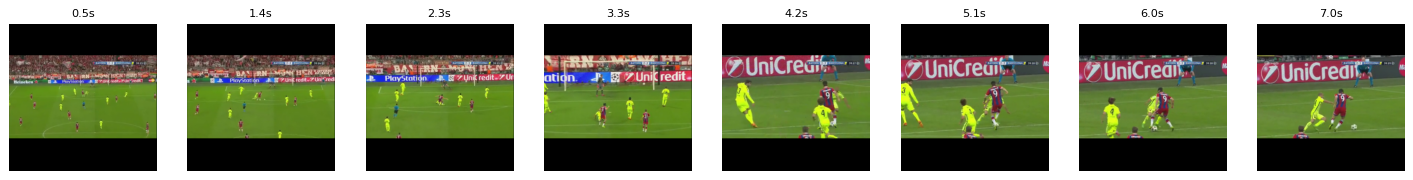

In [4]:
q8 = load_clean("q8")
s = q8[1]
print(mcq_prompt(s))
print("\nđáp án:", s.gold_key)

t0 = time.time()
ev, lp, frames = score(s)
print(f"\n{time.time() - t0:.1f}s")
show_frames(frames, ev.material_ref["timestamps"])

In [5]:
pd.DataFrame({"option": [s.option_texts[k] for k in s.option_keys], "logprob": lp.round(3),
              "p": [round(ev.dist[k], 3) for k in s.option_keys]}, index=s.option_keys)

,option,logprob,p
O1,From Other to Other.,-2.287,0.090
O2,From Main camera center to Close-up corner.,-0.175,0.740
O3,From Spider camera to Public.,-2.075,0.111
O4,From Public to Main camera left.,-2.701,0.059


tổng p = 1.0000000000000002
pred = O2 | confidence = 0.63


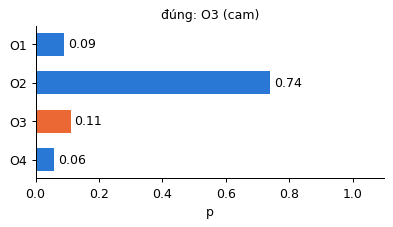

In [6]:
print("tổng p =", sum(ev.dist.values()))
print("pred =", ev.pred, "| confidence =", round(ev.confidence, 3))
plot_dist(ev, s.gold_key)

In [7]:
# so voi cach hoi model sinh cau tra loi tu do
path = s.materials[0]
answer = backend.generate(frames, mcq_prompt(s), duration=probe(path).duration, max_new_tokens=10)
print(repr(answer), "->", parse_answer(answer, s.option_keys, s.option_texts), "| argmax logprob:", ev.pred)

'B' -> None | argmax logprob: O2


## 3. Nhiệt độ

In [8]:
temps = [0.25, 0.5, 1, 2, 4]
rows = [dist_from_logprobs(lp, s.option_keys, T) for T in temps]
df = pd.DataFrame(rows, index=temps).round(3)
df["entropy"] = [round(entropy(d), 3) for d in rows]
df

,O1,O2,O3,O4,entropy
0.25,0.000,0.999,0.000,0.000,0.007
0.50,0.014,0.958,0.021,0.006,0.214
1.00,0.090,0.740,0.111,0.059,0.850
2.00,0.172,0.496,0.192,0.140,1.243
4.00,0.215,0.365,0.227,0.194,1.353


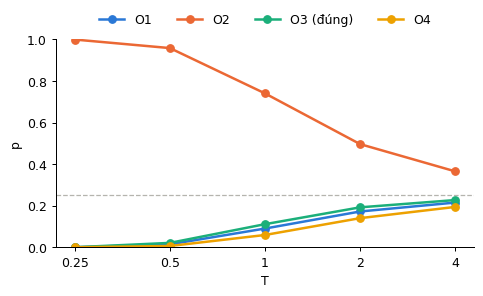

In [9]:
fig, ax = plt.subplots(figsize=(6, 3))
for k, c in zip(s.option_keys, [BLUE, ORANGE, AQUA, YELLOW]):
    ax.plot(temps, df[k], marker="o", color=c, lw=2, label=f"{k}" + (" (đúng)" if k == s.gold_key else ""))
ax.set_xscale("log", base=2); ax.set_xticks(temps, [str(t) for t in temps])
ax.set_xlabel("T"); ax.set_ylabel("p"); ax.set_ylim(0, 1)
ax.axhline(1 / len(s.option_keys), color=GRAY, lw=1, ls="--")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.18))
plt.show()

## 4. 30 câu q8 (dev): nhãn O1-O4 hay A-D

In [10]:
dev = set(build_splits(task_ids=["q8"])["q8"]["dev"])
subset = [x for x in q8 if x.index in dev][:30]

rows = []
t0 = time.time()
for x in subset:
    for letters in [False, True]:
        e, _, _ = score(x, letters=letters)
        rows.append({"nhãn": "A-D" if letters else "O1-O4", "index": x.index, "gold": x.gold_key,
                     "pred": e.pred, "p_gold": e.dist[x.gold_key], "confidence": e.confidence})
allres = pd.DataFrame(rows)
allres["đúng"] = allres.gold == allres.pred
print(f"{len(subset)} mẫu, {(time.time() - t0) / len(subset):.1f}s/mẫu cho cả 2 kiểu, ngẫu nhiên = 0.25")
allres.groupby("nhãn").agg(accuracy=("đúng", "mean"), p_gold=("p_gold", "mean"),
                           confidence=("confidence", "mean")).round(3)

30 mẫu, 1.9s/mẫu cho cả 2 kiểu, ngẫu nhiên = 0.25


,accuracy,p_gold,confidence
nhãn,,,
A-D,0.533,0.478,0.437
O1-O4,0.600,0.373,0.199


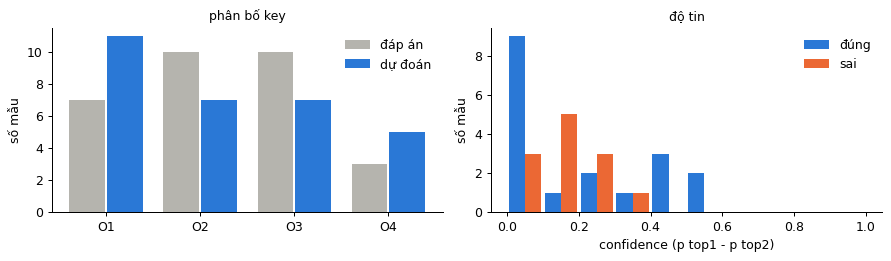

In [11]:
res = allres[allres["nhãn"] == "O1-O4"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
keys = ["O1", "O2", "O3", "O4"]
x = np.arange(4)
axes[0].bar(x - 0.2, [Counter(res.gold)[k] for k in keys], 0.38, color=GRAY, label="đáp án")
axes[0].bar(x + 0.2, [Counter(res.pred)[k] for k in keys], 0.38, color=BLUE, label="dự đoán")
axes[0].set_xticks(x, keys); axes[0].set_ylabel("số mẫu"); axes[0].legend(frameon=False)
axes[0].set_title("phân bố key", fontsize=10)

ok = res.gold == res.pred
axes[1].hist([res.confidence[ok], res.confidence[~ok]], bins=np.linspace(0, 1, 11),
             color=[BLUE, ORANGE], label=["đúng", "sai"], rwidth=0.9)
axes[1].set_xlabel("confidence (p top1 - p top2)"); axes[1].set_ylabel("số mẫu")
axes[1].legend(frameon=False); axes[1].set_title("độ tin", fontsize=10)
plt.tight_layout(); plt.show()

## 5. Các loại Evidence khác

How severe was this foul?
{'O1': 'No card', 'O2': 'No card or yellow card', 'O3': 'Yellow card or red card', 'O4': 'Yellow card'} | đáp án O1
thang: {'O1': 0.0, 'O2': 0.5, 'O3': 1.5, 'O4': 1.0}
giá trị kỳ vọng: 0.775


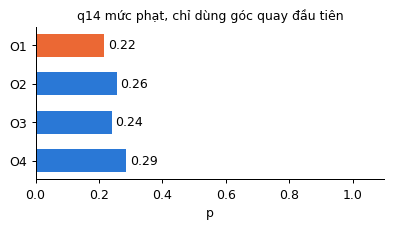

In [12]:
# q14 muc phat: ordinal
q14 = load_clean("q14")
sv = next(x for x in q14 if any(t.lower() == "yellow card" for t in x.option_texts.values()))
_, lp14, _ = score(sv)
ev14 = build_ordinal(backend.name, sv, lp14, ORDINAL_SCALES["severity"])
print(sv.question.split(". ")[-1])
print({k: sv.option_texts[k] for k in sv.option_keys}, "| đáp án", sv.gold_key)
print("thang:", ev14.ordinal_scale)
print("giá trị kỳ vọng:", round(expected_value(ev14), 3))
plot_dist(ev14, sv.gold_key, "q14 mức phạt, chỉ dùng góc quay đầu tiên")

similarity: [0.824 0.807 0.912 0.821] | đáp án O3


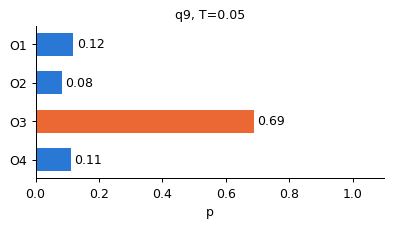

In [13]:
# q9: diem cua tung ung vien la do giong nhau giua embedding replay va ung vien (CLIP)
clip = build_encoder("clip_vit_l")
s9 = load_clean("q9")[0]
emb = [cache.get_embedding(p, 8, 336, clip).astype(np.float32) for p in s9.materials]
sims = np.array([(emb[0] @ e.T).max(axis=1).mean() for e in emb[1:]])
ev9 = build_positional("clip_match", s9, sims)
print("similarity:", sims.round(3), "| đáp án", s9.gold_key)
plot_dist(ev9, s9.gold_key, "q9, T=0.05")

In [14]:
Evidence.failure("foul_tool", ["O1", "O3"], "không đọc được video")

Evidence(tool_name='foul_tool', claim_type='failure', option_keys=['O1', 'O3'], dist={'O1': 0.5, 'O3': 0.5}, confidence=0.0, raw_observation='không đọc được video', material_ref={}, ordinal_scale=None, failed=True)